In [1]:
# Import libraries
import os
import urllib.request
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
# Download and read the dataset
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
file_name = "shakespeare.txt"

if not os.path.exists(file_name):
    urllib.request.urlretrieve(url, file_name)

with open(file_name, "r", encoding="utf-8") as file:
    text = file.read()

print(text[:500])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


Total characters: 1115394
Unique characters: 65
Vocabulary size: 65


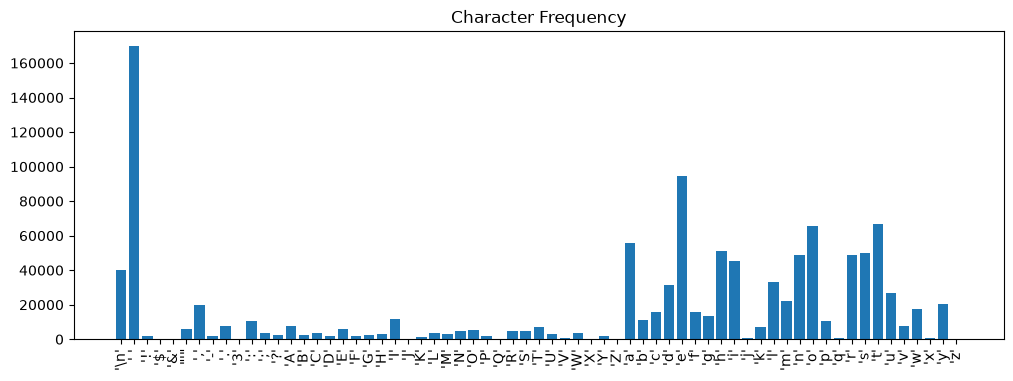

In [3]:
# Basic text analysis
characters = sorted(list(set(text)))
vocab_size = len(characters)

print("Total characters:", len(text))
print("Unique characters:", vocab_size)
print("Vocabulary size:", vocab_size)

# Character frequency
frequency = {char: text.count(char) for char in characters}

plt.figure(figsize=(12, 4))
plt.bar([repr(c) for c in frequency.keys()], frequency.values())
plt.xticks(rotation=90)
plt.title("Character Frequency")
plt.show()

In [4]:
# Create character mappings
char_to_index = {char: i for i, char in enumerate(characters)}
index_to_char = {i: char for char, i in char_to_index.items()}

# Convert text into numbers
data = [char_to_index[char] for char in text]

print("First 20 numbers:", data[:20])

First 20 numbers: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56]


In [5]:
# Create input and target sequences
sequence_length = 100
stride = 3

class TextDataset(Dataset):
    def __init__(self, data):
        self.data = torch.tensor(data, dtype=torch.long)
        self.starts = list(range(0, len(data) - sequence_length - 1, stride))

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, index):
        start = self.starts[index]
        x = self.data[start:start + sequence_length]
        y = self.data[start + 1:start + sequence_length + 1]
        return x, y

dataset = TextDataset(data)
print("Total sequences:", len(dataset))

Total sequences: 371765


In [6]:
# Split data into 90% training and 10% validation
train_size = int(0.9 * len(dataset))
valid_size = len(dataset) - train_size

train_data, valid_data = torch.utils.data.random_split(
    dataset, [train_size, valid_size],
    generator=torch.Generator().manual_seed(42)
)

# Use a smaller number of sequences to make training easier on a normal computer
train_data = torch.utils.data.Subset(train_data, range(min(30000, len(train_data))))
valid_data = torch.utils.data.Subset(valid_data, range(min(3000, len(valid_data))))

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=128)

print("Training sequences:", len(train_data))
print("Validation sequences:", len(valid_data))

Training sequences: 30000
Validation sequences: 3000


In [7]:
# Build a simple two-layer LSTM model
class CharLSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 128)
        self.lstm = nn.LSTM(128, 256, num_layers=2,
                            dropout=0.3, batch_first=True)
        self.output = nn.Linear(256, vocab_size)

    def forward(self, x):
        x = self.embedding(x)
        x, _ = self.lstm(x)
        x = self.output(x)
        return x

model = CharLSTM(vocab_size).to(device)
print(model)

CharLSTM(
  (embedding): Embedding(65, 128)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.3)
  (output): Linear(in_features=256, out_features=65, bias=True)
)


In [8]:
# Loss function and optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 30
train_losses = []
valid_losses = []

In [9]:
# Train the model
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        output = model(x)

        loss = loss_function(
            output.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5)
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)

    # Calculate validation loss
    model.eval()
    total_valid_loss = 0

    with torch.no_grad():
        for x, y in valid_loader:
            x = x.to(device)
            y = y.to(device)
            output = model(x)

            loss = loss_function(
                output.reshape(-1, vocab_size),
                y.reshape(-1)
            )
            total_valid_loss += loss.item()

    valid_loss = total_valid_loss / len(valid_loader)

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print("Epoch:", epoch + 1,
          "Training loss:", round(train_loss, 4),
          "Validation loss:", round(valid_loss, 4),
          "Perplexity:", round(np.exp(min(valid_loss, 20)), 2))

    # Save model after every 5 epochs
    if (epoch + 1) % 5 == 0:
        torch.save(model.state_dict(), f"model_epoch_{epoch + 1}.pth")

Epoch: 1 Training loss: 2.3921 Validation loss: 1.8861 Perplexity: 6.59
Epoch: 2 Training loss: 1.774 Validation loss: 1.6223 Perplexity: 5.06
Epoch: 3 Training loss: 1.6056 Validation loss: 1.509 Perplexity: 4.52
Epoch: 4 Training loss: 1.5195 Validation loss: 1.4437 Perplexity: 4.24
Epoch: 5 Training loss: 1.4638 Validation loss: 1.3983 Perplexity: 4.05
Epoch: 6 Training loss: 1.4237 Validation loss: 1.3662 Perplexity: 3.92
Epoch: 7 Training loss: 1.3928 Validation loss: 1.3378 Perplexity: 3.81
Epoch: 8 Training loss: 1.3675 Validation loss: 1.3187 Perplexity: 3.74
Epoch: 9 Training loss: 1.3462 Validation loss: 1.3011 Perplexity: 3.67
Epoch: 10 Training loss: 1.3275 Validation loss: 1.2845 Perplexity: 3.61
Epoch: 11 Training loss: 1.3107 Validation loss: 1.2706 Perplexity: 3.56
Epoch: 12 Training loss: 1.2968 Validation loss: 1.2578 Perplexity: 3.52
Epoch: 13 Training loss: 1.2831 Validation loss: 1.2463 Perplexity: 3.48
Epoch: 14 Training loss: 1.271 Validation loss: 1.2367 Perplex

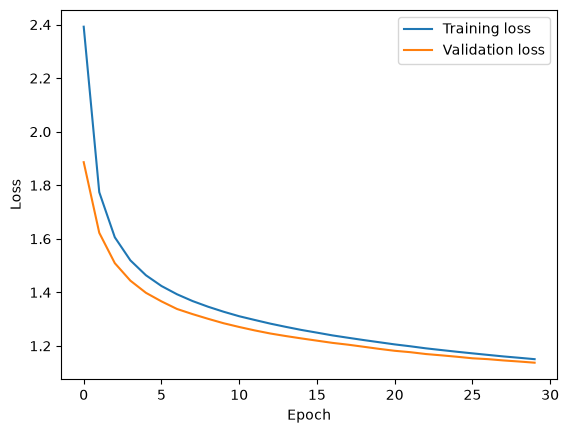

In [10]:
# Show training and validation loss
plt.plot(train_losses, label="Training loss")
plt.plot(valid_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [11]:
# Function to generate text
def generate_text(seed, length=500, temperature=1.0, top_k=None, top_p=None):
    model.eval()

    # Convert seed text to numbers
    seed = "".join(c for c in seed if c in char_to_index)
    if seed == "":
        seed = "ROMEO"

    numbers = [char_to_index[c] for c in seed]
    result = seed

    with torch.no_grad():
        for i in range(length):
            x = torch.tensor([numbers[-100:]], dtype=torch.long).to(device)
            prediction = model(x)[0, -1]
            prediction = prediction / max(temperature, 0.01)
            probabilities = torch.softmax(prediction, dim=0)

            # Top-k sampling
            if top_k is not None:
                values, indices = torch.topk(probabilities, top_k)
                new_probabilities = torch.zeros_like(probabilities)
                new_probabilities[indices] = values
                probabilities = new_probabilities / new_probabilities.sum()

            # Top-p sampling
            if top_p is not None:
                values, indices = torch.sort(probabilities, descending=True)
                total = torch.cumsum(values, dim=0)
                remove = total > top_p
                remove[1:] = remove[:-1].clone()
                remove[0] = False
                values[remove] = 0
                probabilities = torch.zeros_like(probabilities)
                probabilities[indices] = values
                probabilities = probabilities / probabilities.sum()

            next_char = torch.multinomial(probabilities, 1).item()
            numbers.append(next_char)
            result += index_to_char[next_char]

    return result

In [12]:
# Generate text with different temperatures
for temp in [0.2, 0.5, 1.0, 1.2]:
    print("\\nTemperature:", temp)
    print(generate_text("ROMEO:", 500, temperature=temp))

\nTemperature: 0.2
ROMEO:
I will be so for your grace and love to be
The state of honour, and the rest with heaven,
That thou didst stand before the people with him,
And therefore be proved and stand and so far
To be a shrewd and strike and send the world,
Which was not so but a word to be made,
That thou didst prevent the office of the world,
And therefore have been so far off the world.

KING RICHARD III:
Ay, then, as I am not so, so far off them
To see the way to see thee to the princely
Which hath been the prince.


\nTemperature: 0.5
ROMEO:
Soft, sir, I pray thee, let's not for your grace.

KING RICHARD III:
Say that thou hast not so soundly too,
And with the virtue of the gods he will,
Because the shadow of his mercy were a passing
As for the shame of death.

First Murderer:
I thought it would not be seen to be at such
as the people.

LEONTES:
O constable, madam, sir.

CORIOLANUS:
No more, none hath made me fear the world.

ANGELO:
I would the tender word by the wars and here!

K

In [13]:
# Compare top-k and top-p sampling
print("Top-k (k=5):")
print(generate_text("JULIET:", 500, temperature=1.0, top_k=5))

print("\\nTop-k (k=10):")
print(generate_text("HAMLET:", 500, temperature=1.0, top_k=10))

print("\\nTop-p (p=0.9):")
print(generate_text("KING:", 500, temperature=1.0, top_p=0.9))

Top-k (k=5):
JULIET:
O blasting then! Well, well stirr.

LADY ANNE:
With all the confunction of a word.

GREMIO:
Well, who stand up. Companion! what, should not, worthy
What humal is a sisterly destroy?
Or what is heaven?

Citizen:
And to hide thee, for that wise that wise
Of the people, all this to be afreed,
There shall not forget you, and I will say,
I had shortly send my soul to my service,
It was a better suit of me and the world
That short think whem I should have borned him,
And bring a blumis prove a ship, 
\nTop-k (k=10):
HAMLET:
Yes, my good lord.

POMPEY:
Touchest her;
To tell this after true time that does now
His revenge in some horse before he will not:
I wonder that thou didst tender for you.
Brother, thou hast studied to die.

GLOUCESTER:
Her graceful daughter, as was her princely flesh,
And therefore be consider, there were none,
As I am sea, that did now will not: therefore, I
to make me loath to come.

Provost:
This is thy news: he that being once beauth'd, as he
tha

In [14]:
# Generate text from different starting phrases
seeds = ["ROMEO:", "JULIET:", "HAMLET:", "KING:", "To be, or not to be"]

for seed in seeds:
    print("\\nStarting text:", seed)
    print(generate_text(seed, 200, temperature=0.8, top_k=10))

\nStarting text: ROMEO:
ROMEO:
I beseech your honour, sir,
I must be purtued to you for a maid;
For I will give him beg my heir that would bear.

KING RICHARD III:
So do I see; for there is that word it,
That the field of dooms to
\nStarting text: JULIET:
JULIET:
They have soft with your pains to this delight
The clouds have lacked but the duke.

AUFIDIUS:
I would I do.

POLIXENES:
My lord is done: the best of it will we do,
And to the place with the scorn an
\nStarting text: HAMLET:
HAMLET:
Marry, as the gods did not find our father,
That is a man dispatch a sea about it:
Where is the father? what are thee, this is fair
Of door, that he teach your forfeits being stand?

BAPTISTA:
Thanks
\nStarting text: KING:
KING:
No, no; but not so provided! most night on York!
Who dost thou willingly to her with batest?

BUCKINGHAM:
No, I will not know the whores of my soul
I must be bunded, soul to the ground.

ANTIGONUS:
I
\nStarting text: To be, or not to be
To be, or not to be true that the mar

In [15]:
seed_text = "ROMEO:"

for temperature in [0.2, 0.5, 1.0, 1.2]:
    print("\n" + "=" * 60)
    print("Temperature:", temperature)
    print(generate_text(
        seed_text,
        length=500,
        temperature=temperature
    ))


Temperature: 0.2
ROMEO:
What, ho! you men, the worst is not a man.

KING RICHARD III:
What is the cause to the fair duke of him?

BIONDELLO:
I am a prince, and the world shall be a prince.

First Senator:
So shall you be a man that would have stand before
The manner of the dead of the world but that
Which the sea many mounted to them against
The season with a brave three of the sea,
And that the world be so far off a great
As which thou didst be a soldier of the head
And the senate of his power is not so both.

KING R

Temperature: 0.5
ROMEO:
I would I were a woman's age in the life
Of my mother, with the consent of native
That thought of them these faces, which be deposed,
And with the statutes of a father than the world
And from the matter which shows the fire that hath not
been shame to die.

AUFIDIUS:
I will be so in the world they have been
To make a beggar; a part of mine own.

LORD FITZWATER:
The gods he be the country of your absence,
And the white was in many thing it bids,
S

In [16]:
print("Top-k sampling (k=5)")
print(generate_text("JULIET:", length=500, temperature=1.0, top_k=5))

print("\nTop-k sampling (k=10)")
print(generate_text("HAMLET:", length=500, temperature=1.0, top_k=10))

print("\nTop-p sampling (p=0.9)")
print(generate_text("KING:", length=500, temperature=1.0, top_p=0.9))

Top-k sampling (k=5)
JULIET:
When he hath been most dead; so wealthy this,
Attonaties that sunder it, and by a merry law
Which therein affice thou deny the suit of his
face.

LUCIO:
I have not something stand by the word.

KATHARINA:
A good morrow on you till take thou a meal
Whose thoughts to strike to the world.

MENENIUS:
The witch is not the people.

AUFIDIUS:
How now this day not that you shall be
Thus stops me to your highness?

POMPEY:
Sir, I will put our grace.

LEONTES:
Hark! O thou at the feast, I would hide to h

Top-k sampling (k=10)
HAMLET:
With princely presently and harged him;
And, for thy love, together the red, what is the
particular friend, our tremplant abher,
I am the man, being an ignorant town,
One that is not to be accused.' 'Citizens:'
I come not by the most; and so beseech you.

CORIOLANUS:
Here, sister:
The more me to-day in a horse from thence!
I will not plead; for what I will be most,
Though in a warding three for severom,
I could not die to send; and hath

In [17]:
seed_texts = [
    "ROMEO:",
    "JULIET:",
    "HAMLET:",
    "KING:",
    "To be, or not to be"
]

for seed in seed_texts:
    print("\n" + "-" * 60)
    print("Seed:", seed)
    print(generate_text(seed, length=200, temperature=0.8, top_k=10))


------------------------------------------------------------
Seed: ROMEO:
ROMEO:
Ay, all together, make to say the manack of the sun
To my conscience and the duke of solemnish brothers
I will she in life; and all my death-bold:
I would to God all the purpose offence in
court to h

------------------------------------------------------------
Seed: JULIET:
JULIET:
So have you behold your grace to have
The duke in the streeks o' the common body
Upon this sense: these on her sorrow'd lay
That mercy, but not he will not forget:
And, to make an hour in him.

First

------------------------------------------------------------
Seed: HAMLET:
HAMLET:
O sir, thou hast a merry lineal women
Which you shall be a kingly point to meet
A son and twenty the fire of you are.

First Citizen:
And that will some fair. We are at thy blessed
father! what shoul

------------------------------------------------------------
Seed: KING:
KING:
All this noble Petruchio; that's a pardon,
And not so power our patien

In [18]:
# Enter your own starting text
my_seed = input("Enter starting text: ")
my_length = int(input("Enter number of characters to generate: "))
my_temperature = float(input("Enter temperature (0.2, 0.5, 1.0, 1.2): "))

print(generate_text(my_seed, my_length, temperature=my_temperature))

Hello how are you to the princely brother
And therefore be the state of mine own beauty.

First Senator:
Then, madam, I will not be a word to see.

GLOUCESTER:
The present particular subjects that we shall
be a present grave to be the crown.

Second Murderer:
I will be so far as you are a prince,
And therefore be the man that thou hast spoken.

KING RICHARD III:
Then let me see thee but the world that I have
That doth answer the strong presence of the state,
And beg of them, and therefore be the world.

KING RIC


In [19]:
# Example:
model.load_state_dict(torch.load("model_epoch_30.pth", map_location=device))
model.eval()

CharLSTM(
  (embedding): Embedding(65, 128)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.3)
  (output): Linear(in_features=256, out_features=65, bias=True)
)